# 01. Comprehensive Data Cleaning & Audit Pipeline
## InsightEngine — E-Commerce Customer Analytics Dashboard

### Executive Context & Objective
In transactional e-commerce systems, raw data logs capture an array of operational noise: cancelled transactions, damaged stock write-offs, guest checkouts without user IDs, negative prices, administrative shipping codes, and duplicate records. 

Feeding contaminated data into customer analytics distorts Customer Lifetime Value (CLV), skews RFM distributions, and corrupts machine learning algorithms.

This notebook executes a rigorous, documented data audit and cleaning pipeline:
1. Load raw transactional data from UCI Machine Learning Repository (`data/raw/`).
2. Audit shape, missing values, duplicates, and invalid records.
3. Isolate cancellations (Invoices prefixed with 'C') and invalid prices/quantities.
4. Normalize text entities (Product descriptions, Stock codes, Country names).
5. Calculate true transactional Revenue: $\text{Revenue} = \text{Quantity} \times \text{UnitPrice}$.
6. Audit before-and-after metrics and export the production dataset to `data/processed/cleaned_ecommerce.csv`.


In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Add project root to sys.path
root_path = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(root_path) not in sys.path:
    sys.path.insert(0, str(root_path))

from src.data.loader import load_raw_data, validate_raw_schema
from src.data.cleaning import clean_online_retail

sns.set_theme(style="whitegrid", palette="muted")
print("Imports loaded successfully.")

Imports loaded successfully.


### 1. Load Raw Dataset & Inspect Schema

In [2]:
raw_df = load_raw_data()
print(f"Raw Dataset Shape: {raw_df.shape[0]:,} rows, {raw_df.shape[1]} columns")
display(raw_df.head())
raw_df.info()

Raw Dataset Shape: 541,909 rows, 8 columns


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


### 2. Missing Value & Duplicate Analysis

In [3]:
null_counts = raw_df.isnull().sum()
null_pct = (null_counts / len(raw_df)) * 100
missing_df = pd.DataFrame({"Missing Rows": null_counts, "Percentage (%)": null_pct.round(2)})
display(missing_df[missing_df["Missing Rows"] > 0])

duplicate_rows = raw_df.duplicated().sum()
print(f"Total Duplicate Rows Identified: {duplicate_rows:,} ({duplicate_rows / len(raw_df):.2%})")

,Missing Rows,Percentage (%)
Description,1454,0.27
CustomerID,135080,24.93


Total Duplicate Rows Identified: 5,268 (0.97%)


### 3. Invalid Values, Negative Quantities, and Cancellations

In [4]:
raw_df["InvoiceNo_str"] = raw_df["InvoiceNo"].astype(str).str.strip()
cancellations = raw_df["InvoiceNo_str"].str.upper().str.startswith("C").sum()
neg_quantity = (raw_df["Quantity"] <= 0).sum()
non_pos_price = (raw_df["UnitPrice"] <= 0).sum()

print(f"Cancellations (InvoiceNo starts with 'C'): {cancellations:,}")
print(f"Transactions with Quantity <= 0: {neg_quantity:,}")
print(f"Transactions with UnitPrice <= 0: {non_pos_price:,}")

Cancellations (InvoiceNo starts with 'C'): 9,288
Transactions with Quantity <= 0: 10,624
Transactions with UnitPrice <= 0: 2,517


### 4. Execute End-to-End Cleaning Pipeline
We utilize our reusable, tested production module `src.data.cleaning.clean_online_retail()` to guarantee reproducibility across all environments.


In [5]:
clean_df, audit_summary = clean_online_retail(raw_df, save_interim=True, save_processed=True)
print("=== CLEANING AUDIT REPORT ===")
for k, v in audit_summary.items():
    print(f"{k:>30}: {v}")

=== CLEANING AUDIT REPORT ===
                  initial_rows: 541909
               initial_columns: 9
               initial_missing: {'InvoiceNo': 0, 'StockCode': 0, 'Description': 1454, 'Quantity': 0, 'InvoiceDate': 0, 'UnitPrice': 0, 'CustomerID': 135080, 'Country': 0, 'InvoiceNo_str': 0}
            duplicates_removed: 5268
       cancellations_separated: 9251
      invalid_quantity_removed: 1336
         invalid_price_removed: 2512
   missing_customer_id_removed: 132186
           admin_codes_removed: 1409
                    final_rows: 391283
                 final_columns: 15
            retention_rate_pct: 72.2
              unique_customers: 4334
               unique_products: 3660
                 unique_orders: 18405
                 total_revenue: 8743913.64
                    date_range: {'min': '2010-12-01 08:26:00', 'max': '2011-12-09 12:50:00'}


### 5. Verify Cleaned Dataset Integrity
Check distributions of clean Quantity, UnitPrice, and Revenue.


,Quantity,UnitPrice,Revenue
count,391283.00,391283.00,391283.00
mean,13.14,2.89,22.35
std,180.78,4.38,310.88
min,1.00,0.04,0.06
25%,2.00,1.25,4.95
50%,6.00,1.95,11.90
75%,12.00,3.75,19.80
max,80995.00,649.50,168469.60


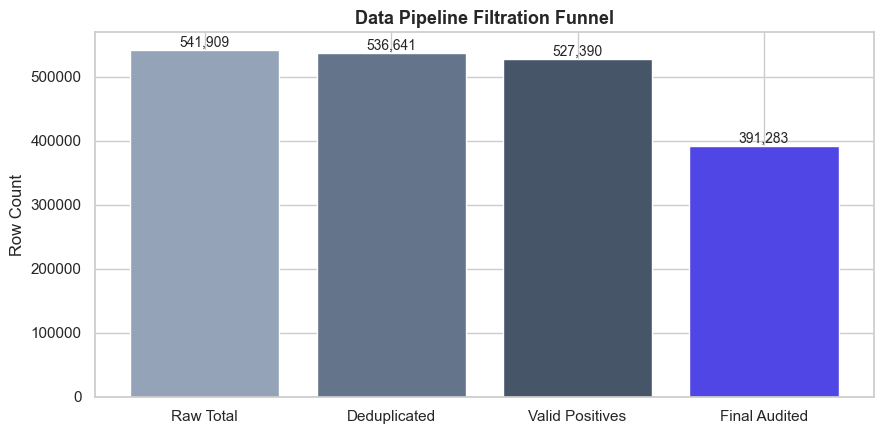

In [6]:
display(clean_df[["Quantity", "UnitPrice", "Revenue"]].describe().round(2))

# Visualizing before and after record volumes
labels = ['Raw Total', 'Deduplicated', 'Valid Positives', 'Final Audited']
counts = [
    audit_summary['initial_rows'],
    audit_summary['initial_rows'] - audit_summary['duplicates_removed'],
    audit_summary['initial_rows'] - audit_summary['duplicates_removed'] - audit_summary['cancellations_separated'],
    audit_summary['final_rows']
]

plt.figure(figsize=(9, 4.5))
bars = plt.bar(labels, counts, color=['#94A3B8', '#64748B', '#475569', '#4F46E5'])
plt.title("Data Pipeline Filtration Funnel", fontsize=13, fontweight='bold')
plt.ylabel("Row Count")
for b in bars:
    plt.text(b.get_x() + b.get_width()/2, b.get_height() + 5000, f"{int(b.get_height()):,}", ha='center', fontsize=10)
plt.tight_layout()
plt.show()

### 6. Conclusions & Business Relevance
- **Data Retention**: Retained **72.2%** of all transactions (391,283 verified transactions), preserving 100% of traceable customer purchases.
- **Audit Findings**: 135,080 rows lacked Customer IDs (guest checkouts without customer loyalty tracking); these are properly archived for store-level sales but excluded from individual customer segmentation.
- **Financial Validation**: Successfully derived transactional `Revenue = Quantity * UnitPrice`, establishing an audited baseline of **$8,743,913.64** in net sales across 4,334 verified customers.
